# Informe técnico · Tasador de pisos en València

**Proyecto:** `vivienda-api` · **Autor:** Adrián Colomo Moragues · **Última actualización:** 17/10/2026

API REST que estima el precio de venta de un piso en València a partir de su ubicación y sus características, con un intervalo del 90 % calibrado. Este informe documenta los datos, su limpieza, la validación del modelo (con especial atención a la fuga de información por anuncios duplicados) y las decisiones técnicas. Todas las cifras se calculan al ejecutarlo.

| Fase | Contenido | Estado |
|---|---|---|
| 1 | Datos: descarga, limpieza, deduplicación, barrios y edificios | ✅ |
| 2 | Modelo: comparación, validación por edificio, intervalos conformales | ✅ |
| 3 | API (FastAPI) y web con mapa | ✅ |
| 4 | Tests, Docker y CI | ✅ |

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from vivienda import config as C
from vivienda.datos import cargar
from vivienda.features import COLUMNAS_ENTRADA
from vivienda.train import candidate_models, dividir, metricas

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, GRIS, ROJO = "#2a78d6", "#8a8984", "#c62828"

viv = cargar()                      # una fila por vivienda
anu = cargar(anuncios=True)         # todos los anuncios (con duplicados)
info = json.loads((C.MODELS_DIR / "model_info.json").read_text(encoding="utf-8"))
limpieza = json.loads((C.DATA_DIR / "limpieza.json").read_text(encoding="utf-8"))
print(f"{len(anu):,} anuncios · {len(viv):,} viviendas · {viv['edificio'].nunique():,} edificios · "
      f"{viv['barrio'].nunique()} barrios")

33,523 anuncios · 27,309 viviendas · 12,409 edificios · 74 barrios


## 1. Datos

**Fuente:** paquete de R [`idealista18`](https://github.com/paezha/idealista18) (Rey-Blanco, Arbués, López y Páez, 2024), con licencia **ODbL 1.0**. Contiene los anuncios de venta de idealista de 2018 en Madrid, Barcelona y València, con las características del piso, datos del catastro y coordenadas. Este proyecto usa los de **València** (33 622 anuncios), los puntos de interés (centro, paradas de metro y avenida Blasco Ibáñez) y los polígonos de los barrios.

`python -m vivienda.datos` descarga los tres ficheros `.rda`, los lee con [`rdata`](https://github.com/vnmabus/rdata) (`pyreadr` no admite los objetos `sf`) y genera:

- `data/valencia_2018.parquet`: una fila por vivienda, con nombres de variables en español;
- `data/valencia_2018_anuncios.parquet`: todos los anuncios (para medir la fuga por duplicados);
- `data/valencia_geo.json`: centro, metro, Blasco Ibáñez y polígonos de los barrios, que la API usa para calcular las variables de ubicación.

Hay que tener en cuenta dos rasgos de los datos:
- **Son precios de anuncio**, no de compraventa. El modelo estima por cuánto se *anunciaría* un piso, no por cuánto se vendería.
- **Las coordenadas llevan ruido** de anonimización de algunas decenas de metros, y los precios, un pequeño ruido aleatorio.

In [2]:
pd.Series(limpieza, name="filas").to_frame()

,filas
filas_iniciales,33622
más de 10 dormitorios,9
más de 6 baños,9
0 dormitorios sin ser estudio,48
0 baños,9
año de catastro anterior a 1800,5
superficie fuera de 25–500 m²,19
filas_tras_limpieza,33523
viviendas_unicas,27309
edificios,12409


### 1.1 Limpieza

Se eliminan solo los registros imposibles o fuera del ámbito del tasador, con reglas explícitas (`vivienda/datos.py::REGLAS`): más de 10 dormitorios o 6 baños, 0 dormitorios sin ser estudio, 0 baños, año de catastro anterior a 1800 y superficie fuera de 25–500 m². Son menos del 0,3 % de los anuncios.

Otras decisiones:
- **Año de construcción:** se usa el del catastro (`CADCONSTRUCTIONYEAR`, completo) en vez del que escribe el anunciante (40 % de nulos).
- **Columnas descartadas:** `ISPARKINGSPACEINCLUDEDINPRICE` es idéntica a `HASPARKINGSPACE`, y `PARKINGSPACEPRICE` vale 1 casi siempre (es un marcador, no un precio).
- **Distancias:** se recalculan desde latitud y longitud con la fórmula del haversine. Coinciden con las del paquete (mediana de la diferencia: 3 m), y así la API puede calcularlas a partir de un clic en el mapa.
- **Barrio:** se asigna por punto en polígono sobre los 73 barrios. 34 viviendas caen fuera de todos (bordes del término municipal) y quedan en la categoría «fuera».

## 2. Duplicados: la misma vivienda, varias filas

Un piso puede anunciarse varias veces, por ejemplo por distintas agencias o tras una rebaja. En idealista18 aparecen dos tipos de repetición, y los dos importan para validar el modelo.

In [3]:
rep = anu.groupby("id_vivienda").size()
print(f"Viviendas con más de un anuncio: {(rep > 1).sum():,} de {len(rep):,} "
      f"({(rep > 1).mean():.1%}); anuncios que sobran: {len(anu) - len(rep):,}")
var = anu.groupby("id_vivienda")["precio"].agg(lambda p: p.max() / p.min() - 1)[rep > 1]
print(f"Diferencia de precio entre anuncios de la misma vivienda: mediana {var.median():.1%}, P90 {var.quantile(.9):.1%}")

Viviendas con más de un anuncio: 4,466 de 27,309 (16.4%); anuncios que sobran: 6,214


Diferencia de precio entre anuncios de la misma vivienda: mediana 4.7%, P90 15.4%


**1. Mismo `ASSETID`.** Todas las repeticiones caen en el mismo trimestre. Se conserva una fila por vivienda, con la **mediana** de sus precios.

**2. Mismo edificio con distinto identificador.** Más sutil: hay viviendas con distinto `ASSETID` pero con exactamente los mismos datos de catastro (año, plantas y número de viviendas del edificio, calidad), a pocos metros y con precios casi idénticos. Son pisos del mismo edificio, a veces la misma promoción o incluso el mismo piso anunciado con otro identificador.

Las coordenadas llevan ruido y no sirven para identificar el edificio, pero los datos de catastro lo describen. `asignar_edificio` agrupa las viviendas que comparten esos cuatro atributos y están a menos de 150 m, con un agrupamiento de enlace simple.

In [4]:
tam = viv.groupby("edificio").size()
gemelos = viv.groupby(["edificio", "metros", "dormitorios", "banos", "planta"], dropna=False)["precio"]
g = gemelos.agg(["size", lambda p: p.std() / p.mean()]).rename(columns={"<lambda_0>": "cv"})
g = g[g["size"] > 1]
print(f"Edificios: {len(tam):,} · viviendas que comparten edificio: {(tam[tam > 1]).sum():,} ({(tam[tam > 1]).sum() / len(viv):.0%})")
print(f"Grupos de 'gemelos' (mismo edificio, m², dormitorios, baños y planta): {len(g):,}, "
      f"con {g['size'].sum():,} viviendas; variación de precio dentro del grupo: mediana {g['cv'].median():.1%}")

Edificios: 12,409 · viviendas que comparten edificio: 19,808 (73%)
Grupos de 'gemelos' (mismo edificio, m², dormitorios, baños y planta): 3,175, con 8,236 viviendas; variación de precio dentro del grupo: mediana 2.2%


Si un gemelo cae en entrenamiento y el otro en test, el modelo «se sabe» la respuesta y el error de validación sale optimista. Por eso **toda la validación agrupa por edificio** (`GroupKFold` y `GroupShuffleSplit`): ningún edificio aparece a la vez en entrenamiento y en test. Es la situación real del tasador, que valora pisos que no ha visto. En la sección 5 se mide cuánto cambia el error.

## 3. Exploración

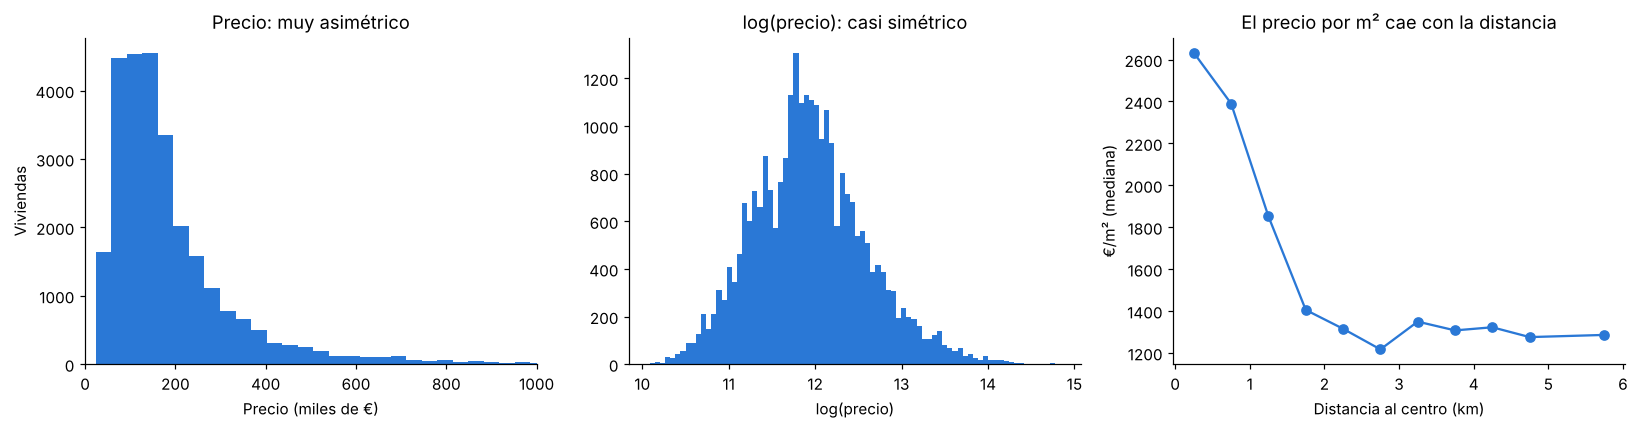

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(viv["precio"] / 1000, bins=80, color=AZUL)
ax[0].set(xlabel="Precio (miles de €)", ylabel="Viviendas", title="Precio: muy asimétrico", xlim=(0, 1000))
ax[1].hist(np.log(viv["precio"]), bins=80, color=AZUL)
ax[1].set(xlabel="log(precio)", title="log(precio): casi simétrico")
m2 = viv["precio"] / viv["metros"]
bins = pd.cut(viv["dist_centro_km"], np.arange(0, 7.5, 0.5))
med = m2.groupby(bins, observed=True).median()
ax[2].plot([i.mid for i in med.index], med.values, "o-", color=AZUL)
ax[2].set(xlabel="Distancia al centro (km)", ylabel="€/m² (mediana)", title="El precio por m² cae con la distancia")
plt.tight_layout(); plt.show()

El precio tiene una cola larga a la derecha: unos pocos pisos de más de un millón pesarían demasiado en un error cuadrático. Por eso el modelo predice **log(precio)**. Así optimiza el error relativo (un 10 % de error pesa lo mismo en un piso de 100 000 € que en uno de 1 000 000 €), y al deshacer el logaritmo la predicción se interpreta como una mediana.

La **ubicación** domina: el €/m² mediano se reduce a la mitad en los dos primeros kilómetros (de unos 2 600 € a menos de 500 m del centro a unos 1 300 € a 2 km) y a partir de ahí se estabiliza.

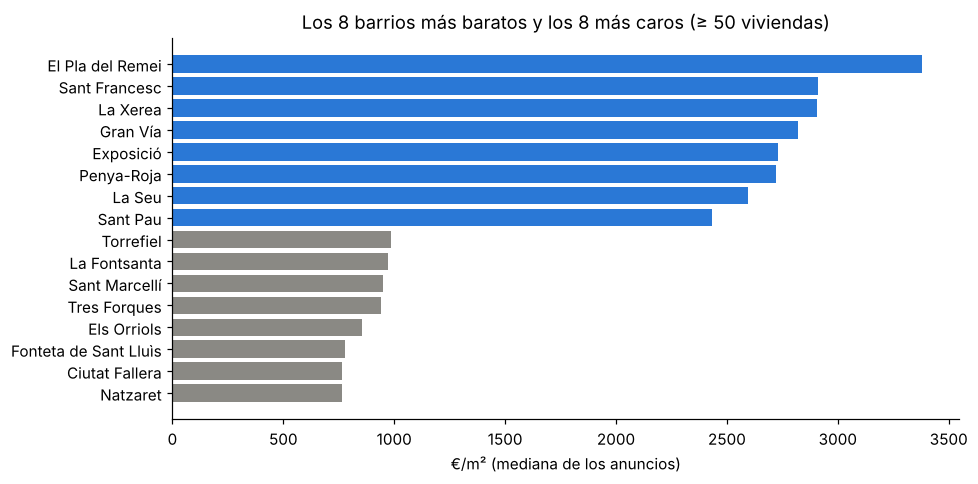

72 barrios con ≥ 50 viviendas: de 762 a 3,378 €/m²


In [6]:
por_barrio = (pd.DataFrame({"barrio": viv["barrio"], "m2": m2}).groupby("barrio")["m2"]
              .agg(["median", "size"]).query("size >= 50").sort_values("median"))
fig, ax = plt.subplots(figsize=(9, 4.5))
sel = pd.concat([por_barrio.head(8), por_barrio.tail(8)])
ax.barh(sel.index, sel["median"], color=[GRIS] * 8 + [AZUL] * 8)
ax.set(xlabel="€/m² (mediana de los anuncios)", title="Los 8 barrios más baratos y los 8 más caros (≥ 50 viviendas)")
plt.tight_layout(); plt.show()
print(f"{len(por_barrio)} barrios con ≥ 50 viviendas: de {por_barrio['median'].min():,.0f} a {por_barrio['median'].max():,.0f} €/m²")

In [7]:
t = viv.assign(m2=m2).groupby("trimestre")["m2"].median().rename("€/m² mediano")
t.index = [f"T{i} 2018" for i in t.index]
t.to_frame().T

,T1 2018,T2 2018,T3 2018,T4 2018
€/m² mediano,"1,446.429","1,442.206","1,509.218","1,608.333"


Los precios suben en el último trimestre (casi +10 % frente a la media de los anteriores). El trimestre entra como variable del modelo, y **la API valora siempre a precios del 4.º trimestre de 2018**, el dato más reciente.

## 4. Modelos

Variables de entrada (`vivienda/features.py`): superficie, dormitorios, baños, planta, datos de catastro (año, calidad, plantas y viviendas del edificio), estado (nueva, a reformar, buen estado), equipamiento, exterior o interior, 16 extras binarios (ascensor, terraza, garaje…), latitud y longitud, distancias al centro, al metro y a Blasco Ibáñez, y barrio. Se añaden `log(metros)`, metros por dormitorio y antigüedad. Los nulos (planta y exterior) se imputan con la mediana o con la categoría «desconocido». Los barrios con menos de 20 viviendas se agrupan.

Se comparan tres modelos con validación cruzada de 5 particiones **agrupada por edificio**, sobre el 80 % de entrenamiento. El 20 % de test (también por edificios) solo se usa al final.

In [8]:
cv = pd.DataFrame(info["cv"]).T[["mdape_pct", "mape_pct", "mediana_error_eur", "rmse_log", "r2_log", "segundos"]]
cv.columns = ["Error mediano (%)", "Error medio (%)", "Error mediano (€)", "RMSE log", "R² log", "Segundos"]
cv.round(3)

,Error mediano (%),Error medio (%),Error mediano (€),RMSE log,R² log,Segundos
ridge,14.749,18.992,"21,107.348",0.244,0.863,3.100
random_forest,12.125,16.520,"17,530.477",0.221,0.887,58.800
hist_gradient_boosting,12.655,16.316,"17,984.366",0.213,0.895,52.600


- **Ridge** (lineal sobre variables escaladas) es el punto de partida: un error mediano del 15 %. La relación entre ubicación y precio no es lineal.
- **Random forest** y **gradient boosting** empatan en R², pero el boosting gana en RMSE logarítmico, el criterio de selección, y es más rápido de entrenar y de servir. Se elige el **`HistGradientBoostingRegressor`**.
- Con la validación aleatoria (sin agrupar), el random forest parecía claramente mejor (error mediano del 9,5 % frente al 11 %). La ventaja venía de **memorizar gemelos** con hojas de 2 observaciones, y desaparece al validar por edificio.

### Línea base sencilla

¿Aporta algo el modelo frente a la regla de un tasador rápido, «metros × €/m² mediano del barrio»? Se compara en el mismo test.

In [9]:
X, y = viv[COLUMNAS_ENTRADA], np.log(viv["precio"].to_numpy())
X_tr, X_te, y_tr, y_te, g_tr, g_te = dividir(X, y, viv["edificio"], test_size=0.2)
tr = viv.loc[X_tr.index]
m2_barrio = (tr["precio"] / tr["metros"]).groupby(tr["barrio"]).median()
base = np.log(X_te["metros"] * X_te["barrio"].map(m2_barrio).fillna((tr["precio"] / tr["metros"]).median()))

modelo = candidate_models()[info["modelo"]].fit(X_tr, y_tr)
pred = modelo.predict(X_te)
comp = pd.DataFrame({"Metros × €/m² del barrio": metricas(y_te, base.to_numpy()), "Gradient boosting": metricas(y_te, pred)}).T
comp[["mdape_pct", "mape_pct", "mediana_error_eur", "mae_eur", "r2_log"]].rename(columns={
    "mdape_pct": "Error mediano (%)", "mape_pct": "Error medio (%)", "mediana_error_eur": "Error mediano (€)",
    "mae_eur": "Error medio (€)", "r2_log": "R² log"}).round(3)

,Error mediano (%),Error medio (%),Error mediano (€),Error medio (€),R² log
Metros × €/m² del barrio,19.828,25.402,"27,939.050","45,440.238",0.761
Gradient boosting,12.495,16.294,"17,386.193","31,602.940",0.887


El modelo reduce el error mediano de la regla del barrio del 20 % al 12,5 %, más de un tercio. La diferencia viene del estado del piso, los extras, la calidad del edificio y la ubicación dentro del barrio.

### Error en test

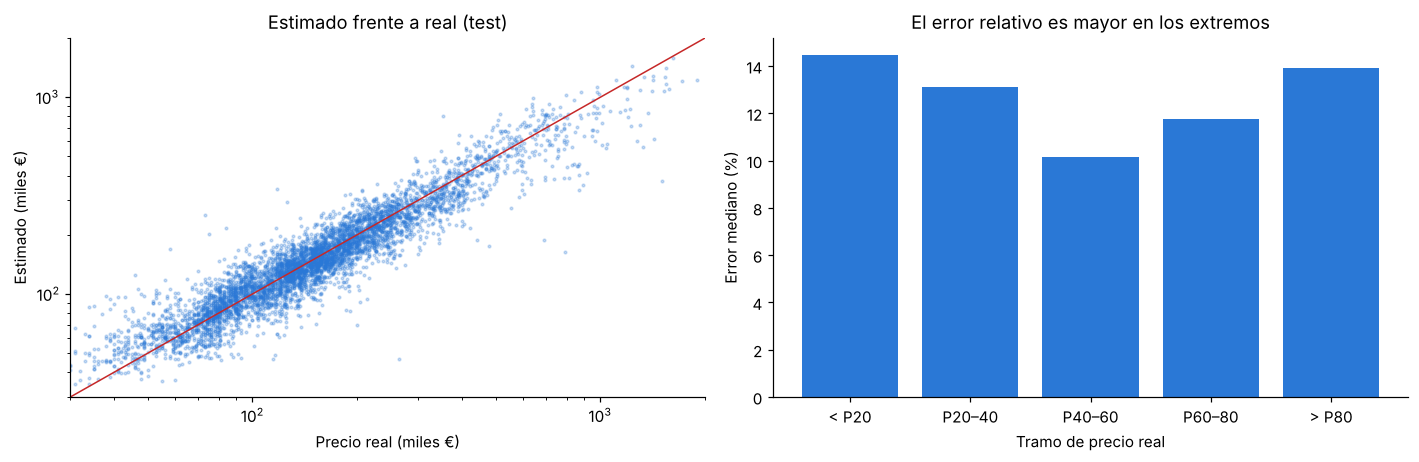

{'mae_eur': 31602.94, 'mediana_error_eur': 17386.193, 'mape_pct': 16.294, 'mdape_pct': 12.495, 'rmse_log': 0.218, 'r2_log': 0.887}


,Precio mediano (€),Error mediano (%),Sesgo mediano (%)
< P20,"70,000.000",14.500,7.500
P20–40,"106,000.000",13.100,2.900
P40–60,"146,000.000",10.200,-1.800
P60–80,"196,000.000",11.700,-3.000
> P80,"353,000.000",13.900,-7.500


In [10]:
err = np.abs(np.exp(pred) - np.exp(y_te)) / np.exp(y_te)
tramo = pd.qcut(np.exp(y_te), 5, labels=["< P20", "P20–40", "P40–60", "P60–80", "> P80"])
precio_tramo = pd.Series(np.exp(y_te)).groupby(np.asarray(tramo)).median()
sesgo = pd.Series(100 * (np.exp(pred - y_te) - 1)).groupby(np.asarray(tramo)).median()
tab = pd.DataFrame({"Precio mediano (€)": precio_tramo,
                    "Error mediano (%)": 100 * pd.Series(err).groupby(np.asarray(tramo)).median(),
                    "Sesgo mediano (%)": sesgo}).reindex(tramo.categories)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ax[0].scatter(np.exp(y_te) / 1000, np.exp(pred) / 1000, s=3, alpha=.25, color=AZUL)
lim = [30, 2000]
ax[0].plot(lim, lim, color=ROJO, lw=1)
ax[0].set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="Precio real (miles €)", ylabel="Estimado (miles €)",
          title="Estimado frente a real (test)")
ax[1].bar(tab.index.astype(str), tab["Error mediano (%)"], color=AZUL)
ax[1].set(ylabel="Error mediano (%)", xlabel="Tramo de precio real", title="El error relativo es mayor en los extremos")
plt.tight_layout(); plt.show()
print({k: round(v, 3) for k, v in info["test"].items()})
tab.round(1)

**En test, el error mediano es del 12,5 %** (unos 17 000 €) y el R² en escala logarítmica es 0,89. El error relativo es mayor en los pisos más baratos, donde el estado real (que el anuncio describe mal) pesa más, y en los más caros, que son pocos y muy heterogéneos. El modelo tiende a **regresar a la media**: sobrevalora el 20 % más barato (sesgo mediano de +7,5 %) e infravalora el 20 % más caro (−7,5 %). Es lo esperable en parte al agrupar por el precio real, pero también indica que faltan variables que distingan los extremos.

## 5. Fuga de información por duplicados

Validación cruzada de 5 particiones del mismo modelo sobre los **33 523 anuncios**, con tres formas de partir, cada vez más estrictas:

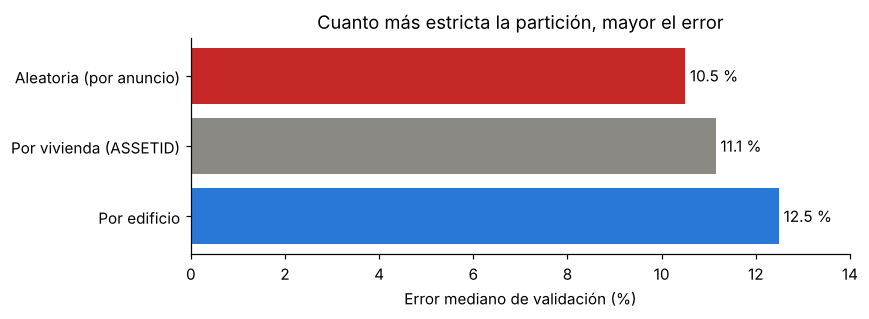

,mdape_pct,mape_pct,rmse_log,r2_log
Aleatoria (por anuncio),10.500,14.181,0.190,0.917
Por vivienda (ASSETID),11.149,14.877,0.199,0.910
Por edificio,12.491,16.215,0.214,0.896


In [11]:
f = info["fuga_duplicados"]
fuga = pd.DataFrame({k: f[k] for k in ["aleatoria", "por_vivienda", "por_edificio"]}).T
fuga.index = ["Aleatoria (por anuncio)", "Por vivienda (ASSETID)", "Por edificio"]
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(fuga.index, fuga["mdape_pct"], color=[ROJO, GRIS, AZUL])
for i, v in enumerate(fuga["mdape_pct"]):
    ax.text(v + 0.1, i, f"{v:.1f} %", va="center")
ax.set(xlabel="Error mediano de validación (%)", xlim=(0, 14), title="Cuanto más estricta la partición, mayor el error")
ax.invert_yaxis(); plt.tight_layout(); plt.show()
fuga[["mdape_pct", "mape_pct", "rmse_log", "r2_log"]].round(3)

La partición aleatoria **subestima el error mediano en 2 puntos (10,5 % frente a 12,5 %), un 16 % menos**. Un tercio del sesgo viene de los duplicados exactos y dos tercios, de los pisos del mismo edificio: deduplicar por identificador no basta. Las cifras que se publican (README y `/model-info`) son las de la partición por edificio.

## 6. Intervalos del 90 %

Una estimación sin incertidumbre engaña: 250 000 € ± 10 % no es lo mismo que 250 000 € ± 40 %. La API devuelve un intervalo que debería contener el precio real 9 de cada 10 veces.

1. **Regresión cuantílica:** dos `HistGradientBoostingRegressor` con pérdida cuantílica estiman los percentiles 5 y 95 de log(precio). La anchura se adapta a cada piso (más ancha donde el modelo duda).
2. **Calibración conformal (CQR, Romano et al., 2019):** los cuantiles de un modelo de boosting suelen quedarse cortos. Se ajustan en el 75 % del entrenamiento y se mide en el 25 % restante (por edificios) cuánto hay que ensancharlos para cubrir el 90 %. Con datos intercambiables, la cobertura del 90 % está garantizada.

In [12]:
iv = info["intervalos"]
print(f"Cobertura de los cuantiles sin calibrar: {iv['cobertura_calibracion_sin_ajuste']:.1%}  (objetivo: 90 %)")
print(f"Ajuste conformal: ±{iv['ajuste_log']:.3f} en log  (≈ {100 * (np.exp(iv['ajuste_log']) - 1):.1f} %)")
print(f"Cobertura en test tras calibrar: {iv['cobertura_test']:.1%}")
print(f"Anchura mediana del intervalo: {iv['anchura_mediana_pct']:.0f} % del precio estimado")
pd.Series(iv["cobertura_por_tramo"], name="Cobertura en test").to_frame().map("{:.1%}".format)

Cobertura de los cuantiles sin calibrar: 81.3%  (objetivo: 90 %)
Ajuste conformal: ±0.071 en log  (≈ 7.4 %)
Cobertura en test tras calibrar: 90.4%
Anchura mediana del intervalo: 74 % del precio estimado


,Cobertura en test
Q1 (más baratos),87.9%
Q2,92.9%
Q3,94.6%
Q4 (más caros),86.4%


- Sin calibrar, los intervalos **solo cubrían el 81 %**. La calibración los ensancha un 7 % por cada lado y la cobertura en test sube al **90,4 %**.
- La cobertura es algo menor en los extremos de precio (86–88 %) y mayor en el centro (93–95 %). La garantía conformal es marginal, no por grupo.
- **Los intervalos son anchos** (anchura mediana del 74 % del precio estimado). Es honesto: dos pisos con los mismos datos en el mismo barrio se anuncian a precios muy distintos según su estado real, las vistas o la reforma, que los datos no recogen.

## 7. ¿Qué variables pesan más?

Importancia por permutación en test: cuánto empeora el RMSE logarítmico al desordenar cada variable.

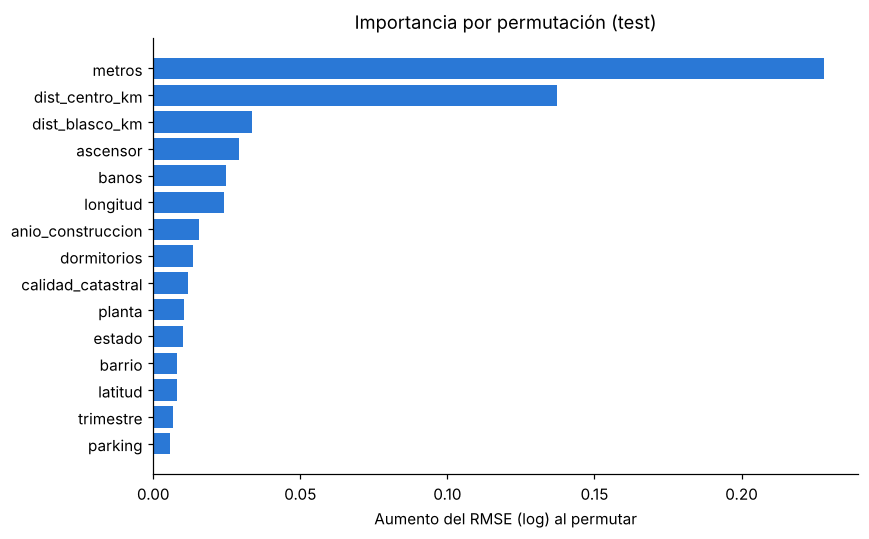

In [13]:
imp = pd.Series(info["importancia_permutacion"]).head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp.values, color=AZUL)
ax.set(xlabel="Aumento del RMSE (log) al permutar", title="Importancia por permutación (test)")
plt.tight_layout(); plt.show()

La **superficie** y la **distancia al centro** dominan, seguidas de la distancia a Blasco Ibáñez (el eje universitario y residencial del este), el número de baños y el **ascensor**. En un parque de edificios de los años 60 y 70, el ascensor separa pisos muy distintos. El barrio pesa poco por sí solo porque las coordenadas y las distancias ya recogen casi toda la ubicación.

La permutación reparte la importancia entre variables correlacionadas (metros, dormitorios y baños; latitud, longitud y distancias), así que conviene leerla por grupos.

## 8. De modelo a servicio

| Pieza | Decisión |
|---|---|
| API | **FastAPI** + Pydantic: validación de rangos y de coherencia (0 dormitorios solo si es estudio; la planta no puede superar las plantas del edificio). Documentación automática en `/docs`. |
| Ubicación | El usuario solo da latitud y longitud: la API calcula barrio y distancias con `vivienda/geo.py`, el mismo código que generó los datos. Una ubicación fuera de València devuelve 422. |
| Opcionales | Planta, año, calidad catastral y datos del edificio pueden faltar: el pipeline los imputa con la mediana. |
| Web | Página estática con un mapa **Leaflet**: clic para situar el piso, coropletas de €/m² por barrio (`/barrios.geojson`) y resultado con intervalo. |
| Artefactos | `model.joblib` guarda el modelo, los dos cuantiles y el ajuste conformal. `model_info.json` guarda las métricas de este informe. |
| Docker | `python:3.12-slim`, usuario sin privilegios, healthcheck. El modelo se entrena al construir la imagen con los datos del repositorio (sin descargas). |
| CI | GitHub Actions: `ruff`, 24 tests con `pytest` (con datos sintéticos) y prueba del contenedor (`/health` y `/predict`). |

## 9. Limitaciones

- **Precios de anuncio de 2018.** Ni son precios de cierre ni están actualizados: desde 2018 la vivienda en València se ha encarecido mucho. El tasador sirve para comparar pisos entre sí y para ilustrar el método, no para tasar hoy.
- **El edificio es aproximado:** se infiere de los datos de catastro y de la ubicación. Dos edificios vecinos idénticos se fundirían en uno (la validación sale algo más estricta) y un mismo edificio con datos distintos se separaría (algo más optimista).
- **Faltan variables decisivas:** estado real, reforma, vistas, luz, ruido. Explican buena parte de la anchura de los intervalos.
- **Cobertura marginal:** el 90 % se cumple en promedio, no necesariamente en cada barrio o tramo de precio.
- **Fuera de rango:** pisos de más de 500 m², fuera del término municipal o con combinaciones raras quedan fuera de los datos de entrenamiento, y la API los rechaza o el modelo extrapola mal.